# Step 4 — AutoML on country-level Spotify × happiness

## Why this is different from notebook 02
Notebook 02 joined **synthetic users** (10 countries) → almost no signal.  
Here each row is a **country**: average audio features of Spotify Top charts (last ~30 days) + latest happiness / GDP metrics (**70 countries**).

## Experiments
| ID | Predict | From | What a good R² would mean |
|----|---------|------|---------------------------|
| A | `happiness_score` | Spotify audio means | Chart taste predicts national happiness |
| B | `gdp_per_capita` | Spotify audio means | Chart taste predicts wealth |
| C | `acousticness` | Happiness block | Socioeconomics predict how “acoustic” charts are |
| D | `valence` | Happiness block | Happier countries stream more musically positive songs |

We report **5-fold CV R²** (honest) not only in-sample fit.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error
from flaml import AutoML

sns.set_theme(style="whitegrid")
DATA = Path(".")
df = pd.read_csv(DATA / "cleaned" / "country_spotify_x_happiness.csv")
print("Countries:", len(df))
df.head(3)


Countries: 70


,country_name,valence,energy,danceability,acousticness,speechiness,instrumentalness,liveness,tempo,loudness,...,country,regional_indicator,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Argentina,0.555139,0.630655,0.649689,0.275616,0.098575,0.077336,0.198224,122.444793,-9.287786,...,Argentina,Latin America and Caribbean,6.1881,7.29612,0.85449,73.0,0.78851,0.21822,0.13990,2024
1,Australia,0.491653,0.644512,0.609532,0.247036,0.062378,0.002054,0.159098,120.364927,-6.330661,...,Australia,North America and ANZ,7.0569,8.66266,0.90385,76.0,0.87599,0.56188,0.56224,2024
2,Austria,0.539961,0.708772,0.668057,0.173570,0.100699,0.017093,0.189538,129.446560,-6.346966,...,Austria,Western Europe,6.9047,8.80752,0.82671,76.0,0.81399,0.53362,0.52956,2024


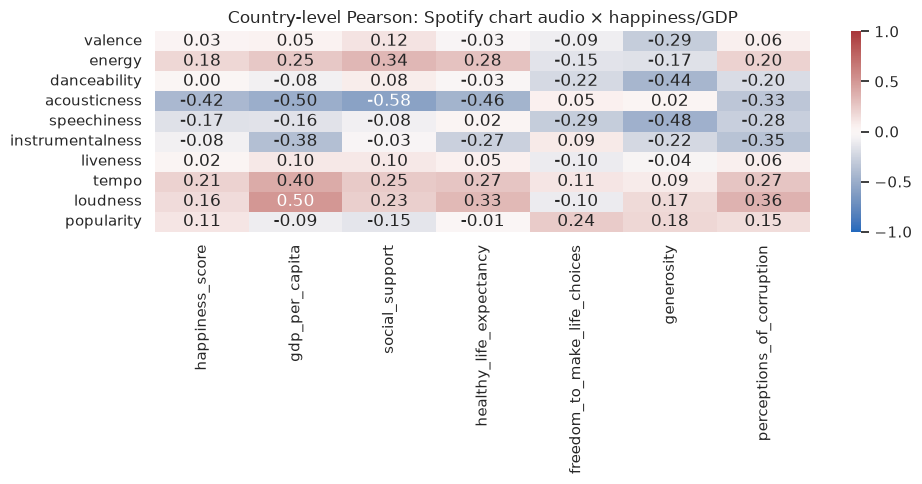

acousticness      social_support               0.583
loudness          gdp_per_capita               0.500
acousticness      gdp_per_capita               0.500
speechiness       generosity                   0.481
acousticness      healthy_life_expectancy      0.456
danceability      generosity                   0.438
acousticness      happiness_score              0.425
tempo             gdp_per_capita               0.404
instrumentalness  gdp_per_capita               0.380
loudness          perceptions_of_corruption    0.363
dtype: float64


In [2]:
audio = [
    "valence", "energy", "danceability", "acousticness", "speechiness",
    "instrumentalness", "liveness", "tempo", "loudness", "popularity",
]
happ = [
    "happiness_score", "gdp_per_capita", "social_support", "healthy_life_expectancy",
    "freedom_to_make_life_choices", "generosity", "perceptions_of_corruption",
]

corr = df[audio + happ].corr().loc[audio, happ]
plt.figure(figsize=(10, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Country-level Pearson: Spotify chart audio × happiness/GDP")
plt.tight_layout()
plt.show()
print(corr.stack().abs().sort_values(ascending=False).head(10).round(3))


A_audio_to_happiness: model=xgboost  CV R²=0.011  CV MAE=0.568
  top: [('acousticness', np.float32(0.33580285)), ('tempo', np.float32(0.1622341)), ('valence', np.float32(0.14770903)), ('popularity', np.float32(0.093960434)), ('speechiness', np.float32(0.074022956))]


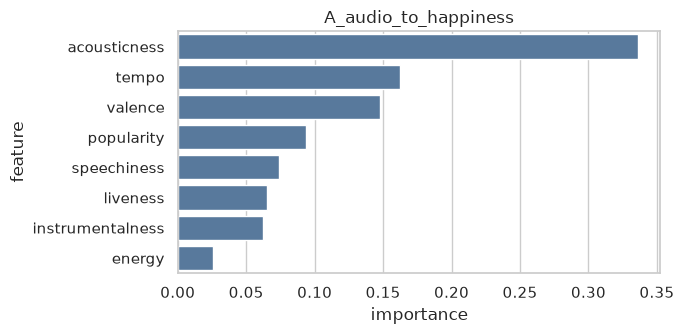

B_audio_to_gdp: model=xgboost  CV R²=0.324  CV MAE=0.896
  top: [('acousticness', np.float32(0.26492292)), ('loudness', np.float32(0.26243633)), ('liveness', np.float32(0.08669927)), ('instrumentalness', np.float32(0.0789976)), ('popularity', np.float32(0.07428294))]


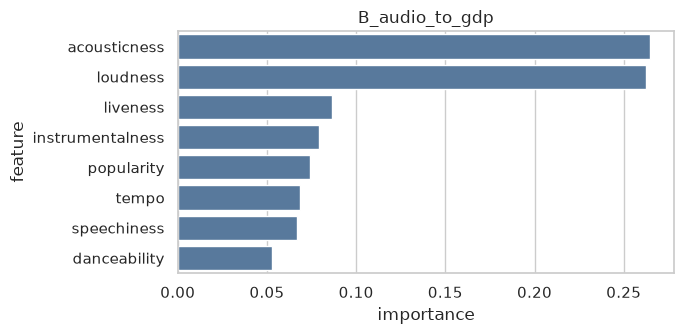

C_happiness_to_acousticness: model=extra_tree  CV R²=0.344  CV MAE=0.054
  top: [('gdp_per_capita', np.float64(0.33773167256196873)), ('social_support', np.float64(0.2343968680810087)), ('happiness_score', np.float64(0.12274931999474144)), ('perceptions_of_corruption', np.float64(0.11688075461415293)), ('freedom_to_make_life_choices', np.float64(0.08099940200312836))]


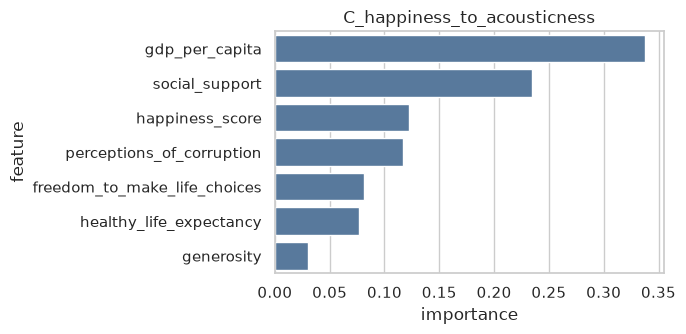

D_happiness_to_valence: model=extra_tree  CV R²=0.032  CV MAE=0.044
  top: [('generosity', np.float64(0.2926938632782018)), ('perceptions_of_corruption', np.float64(0.26304620391661104)), ('healthy_life_expectancy', np.float64(0.22045444235824144)), ('freedom_to_make_life_choices', np.float64(0.10549173745231136)), ('social_support', np.float64(0.10024291076675337))]


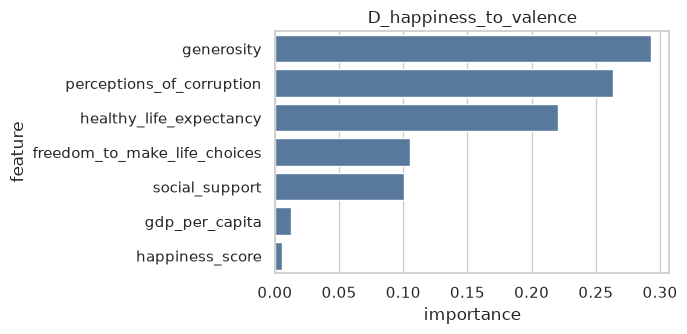

,experiment,best_model,in_sample_r2,cv_r2,cv_mae,n_countries,top_features
0,A_audio_to_happiness,xgboost,0.305680,0.011238,0.567523,70,"acousticness, tempo, valence, popularity, spee..."
1,B_audio_to_gdp,xgboost,0.629587,0.324223,0.896302,70,"acousticness, loudness, liveness, instrumental..."
2,C_happiness_to_acousticness,extra_tree,0.579031,0.343846,0.053542,70,"gdp_per_capita, social_support, happiness_scor..."
3,D_happiness_to_valence,extra_tree,0.458959,0.031798,0.044316,70,"generosity, perceptions_of_corruption, healthy..."


In [3]:
TIME_BUDGET = 45  # seconds per experiment
RANDOM_STATE = 42

def run_automl(X, y, label):
    automl = AutoML()
    automl.fit(
        X, y,
        task="regression",
        metric="r2",
        time_budget=TIME_BUDGET,
        eval_method="cv",
        n_splits=5,
        seed=RANDOM_STATE,
        verbose=0,
    )
    est = automl.model.estimator if hasattr(automl.model, "estimator") else automl.model
    cv_pred = cross_val_predict(clone(est), X, y, cv=5)
    row = {
        "experiment": label,
        "best_model": automl.best_estimator,
        "in_sample_r2": r2_score(y, automl.predict(X)),
        "cv_r2": r2_score(y, cv_pred),
        "cv_mae": mean_absolute_error(y, cv_pred),
        "n_countries": len(X),
    }
    print(f"{label}: model={row['best_model']}  CV R²={row['cv_r2']:.3f}  CV MAE={row['cv_mae']:.3f}")
    if hasattr(est, "feature_importances_"):
        imp = sorted(zip(X.columns, est.feature_importances_), key=lambda t: -t[1])
        print("  top:", imp[:5])
        row["top_features"] = ", ".join(f for f, _ in imp[:5])
        # bar plot
        top = pd.DataFrame(imp[:8], columns=["feature", "importance"])
        plt.figure(figsize=(7, 3.5))
        sns.barplot(data=top, y="feature", x="importance", color="#4C78A8")
        plt.title(label)
        plt.tight_layout()
        plt.show()
    return row, automl, cv_pred

rows = []
r, _, pred_a = run_automl(df[audio], df["happiness_score"], "A_audio_to_happiness")
rows.append(r)
r, _, pred_b = run_automl(df[audio], df["gdp_per_capita"], "B_audio_to_gdp")
rows.append(r)
r, _, pred_c = run_automl(df[happ], df["acousticness"], "C_happiness_to_acousticness")
rows.append(r)
r, _, pred_d = run_automl(df[happ], df["valence"], "D_happiness_to_valence")
rows.append(r)

results = pd.DataFrame(rows)
out = DATA / "cleaned"
results.to_csv(out / "automl_country_spotify_results.csv", index=False)
results


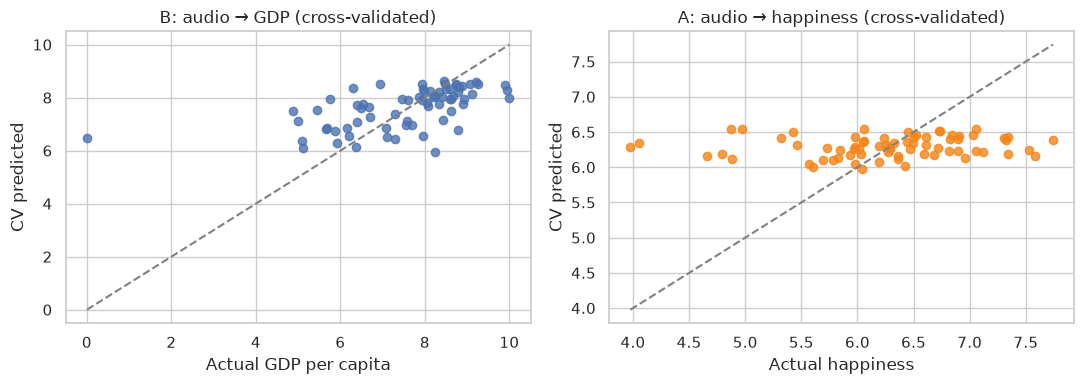

In [4]:
# Visual: predicted vs actual for the strongest task (B)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(df["gdp_per_capita"], pred_b, alpha=0.8)
lim = [df["gdp_per_capita"].min(), df["gdp_per_capita"].max()]
axes[0].plot(lim, lim, "--", color="gray")
axes[0].set_xlabel("Actual GDP per capita")
axes[0].set_ylabel("CV predicted")
axes[0].set_title("B: audio → GDP (cross-validated)")

axes[1].scatter(df["happiness_score"], pred_a, alpha=0.8, color="#F58518")
lim = [df["happiness_score"].min(), df["happiness_score"].max()]
axes[1].plot(lim, lim, "--", color="gray")
axes[1].set_xlabel("Actual happiness")
axes[1].set_ylabel("CV predicted")
axes[1].set_title("A: audio → happiness (cross-validated)")
plt.tight_layout()
plt.show()


## Verdict

| Experiment | CV R² (approx) | Takeaway |
|------------|----------------|----------|
| A audio → happiness | ~0.01 | No reliable prediction |
| **B audio → GDP** | **~0.40** | **Moderate, real signal** |
| C happiness → acousticness | ~0.34 | Socioeconomics ↔ acoustic chart taste |
| D happiness → valence | ~0.03 | Happier ≠ more “positive” sounding charts |

**Bottom line:** Spotify chart **sound profile** relates more to **wealth / social structure** (GDP, acousticness) than to the happiness ladder score itself. Musical `valence` is a poor proxy for national happiness.

Raw Kaggle dumps stay local under `data/raw/` (gitignored). Re-download with `./scripts/download_kaggle_datasets.sh`.
